# Figure 4 — Hippo signaling promotes ETV2 and suppresses alternative lateral-mesoderm fates

This notebook reproduces computational panels **c, d, and e**. Panels a and b are experimental qPCR and flow-cytometry panels and are not generated here.

- **Panel c:** D1-to-D2 marker-gene and projected-program dotplots across Hippo-modulator conditions.
- **Panel d:** P15/P17 and representative marker UMAPs.
- **Panel e:** integrated P15/P17 regulator effects, gene loadings, motif enrichment, and motif logos.

Panel c uses Scanpy dotplots, panel d uses plotnine, and panel e uses Matplotlib and logomaker.

## Input requirements

The processed Hippo expression object and fixed-reference cNMF projection are specified in the active path configuration. Before plotting, the analysis verifies complete cell coverage, program labels, and the condition-specific quality-control fields required by the time-course panels.


In [ ]:
# Repository-path bootstrap for local support modules.
from pathlib import Path
import sys


def _find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "src" / "cc_perturbseq").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root containing "
        "src/cc_perturbseq. Run this notebook from within the "
        "cc-perturbseq-manuscript-analysis checkout."
    )


REPO_ROOT = _find_repo_root()
for _support_path in (REPO_ROOT, REPO_ROOT / "src"):
    _support_path_text = str(_support_path)
    if _support_path_text not in sys.path:
        sys.path.insert(0, _support_path_text)

print(
    "Repository support paths added:",
    REPO_ROOT,
    "and",
    REPO_ROOT / "src",
)


Repository support paths added: /oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction and /oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction/src


In [2]:
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

from src.cc_perturbseq.figure_notebook import (
    get_path,
    initialize_figure,
    panel_directory,
    sha256_file,
    write_receipt,
)
from src.cc_perturbseq.figure4_panels import (
    FIGURE4C_CONDITION_ORDER,
    FIGURE4C_PROGRAMS,
    FIGURE4D_FEATURES,
    make_figure4e_annotation,
    plot_figure4d_feature_umaps,
    prepare_figure4c_dotplots,
)
from src.cc_perturbseq.program_panels import load_integrated_anndata

EXPECTED_WORKBOOK_SHA256 = (
    "d2fe4834b1efd3c00e01062b56b907a6178bfbc48a40beb5ea7b347538bfc824"
)


def export_plotnine(plot, panel, stem):
    out = panel_directory(ctx, panel)
    result = {}
    for suffix in ("pdf", "svg", "png"):
        path = out / f"{stem}.{suffix}"
        plot.save(filename=path, dpi=300, verbose=False)
        result[suffix] = str(path)
    return result


def export_matplotlib(figure, panel, stem):
    out = panel_directory(ctx, panel)
    result = {}
    for suffix in ("pdf", "svg", "png"):
        path = out / f"{stem}.{suffix}"
        kwargs = {"dpi": 300} if suffix == "png" else {}
        figure.savefig(
            path,
            bbox_inches="tight",
            facecolor="white",
            transparent=False,
            **kwargs,
        )
        result[suffix] = str(path)
    return result


def export_scanpy_dotplot(dotplot, panel, stem):
    out = panel_directory(ctx, panel)
    result = {}
    for suffix in ("pdf", "svg", "png"):
        path = out / f"{stem}.{suffix}"
        dotplot.savefig(path)
        result[suffix] = str(path)
    return result


FIGURE = {
    "figure_id": "Figure_04",
    "title": "Figure 4 — Hippo signaling promotes ETV2 and suppresses alternative lateral-mesoderm fates",
    "scope": "Panels c–e; panels a–b omitted",
    "manuscript": "Working CC-Perturb-seq EC Differentiation - Text V3",
    "panels": [
        {
            "panel": "c",
            "description": "D1-to-D2 Hippo-modulator marker-gene and projected-program dotplots",
            "type": "code",
            "required_inputs": [
                "hippo_timecourse.query_h5ad",
                "hippo_timecourse.reprojected_cnmf_h5ad",
            ],
        },
        {
            "panel": "d",
            "description": "P15/P17 and FLI1/SLC8A1 UMAPs",
            "type": "code",
            "required_inputs": [
                "ccperturbseq.integrated_anndata",
                "ccperturbseq.cnmf_usage",
            ],
        },
        {
            "panel": "e",
            "description": "Integrated P15/P17 regulator, loading, and motif annotation",
            "type": "mixed",
            "required_inputs": [
                "ccperturbseq.cnmf_spectra",
                "multiome.enhancer_enrichment_results",
                "multiome.cluster_motif_map",
                "multiome.modisco_compiled_h5",
            ],
        },
    ],
}
ctx = initialize_figure(FIGURE)

workbook = (
    ctx["root"]
    / "data"
    / "figure_02"
    / "cNMF_50_0_2_032526_6co.xlsx"
)
workbook_hash = sha256_file(workbook) if workbook.exists() else None
if workbook_hash != EXPECTED_WORKBOOK_SHA256:
    raise ValueError(
        "Missing or incorrect repository-local cNMF workbook at "
        f"{workbook}. Observed SHA-256={workbook_hash}; "
        f"expected {EXPECTED_WORKBOOK_SHA256}."
    )

ctx["input_audit"]

,key,path,exists,is_file,is_dir,size_bytes,error
0,ccperturbseq.cnmf_spectra,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,True,True,False,8502837,None
1,ccperturbseq.cnmf_usage,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,True,True,False,51382087,None
2,ccperturbseq.integrated_anndata,/oak/stanford/groups/engreitz/Users/opushkar/c...,True,True,False,4218513308,None
3,hippo_timecourse.query_h5ad,/oak/stanford/groups/engreitz/Users/tri/Hippo_...,True,True,False,15979592094,None
4,hippo_timecourse.reprojected_cnmf_h5ad,/oak/stanford/groups/engreitz/Users/tri/Hippo_...,True,True,False,199451782,None
5,multiome.cluster_motif_map,/oak/stanford/groups/engreitz/Users/opushkar/m...,True,True,False,75056,None
6,multiome.enhancer_enrichment_results,/oak/stanford/groups/engreitz/Users/opushkar/m...,True,True,False,1205371,None
7,multiome.modisco_compiled_h5,/oak/stanford/groups/engreitz/Users/opushkar/m...,True,True,False,468352,None


## Panel c — D1-to-D2 marker-gene and program dotplots

The analysis retains condition-specific QC-passing cells, excludes sublibrary `s8`, normalizes and log-transforms marker-gene expression, and displays P15 and P17 from `obsm["X_cnmf_clr_top_specific_200"]` using the specified D1-to-D2 condition order.


/oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction/src/cc_perturbseq/figure4_panels_legacy.py:140: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD116-1', 'SNORD116-2', 'SNORD116-3', 'SNORD116-4', 'SNORD116-5']


{'n_common_cells': 212890,
 'n_D1_to_D2_QC_cells': 56278,
 'conditions': ['D1 Control',
  'D1.33 Control',
  'D1.67 Control',
  'D2 Control',
  'D1-1.33 HIPPOa',
  'D1-1.67 HIPPOa',
  'D1-2 HIPPOa',
  'D1-1.33 HIPPOi',
  'D1-1.67 HIPPOi',
  'D1-2 HIPPOi'],
 'program_projection': 'X_cnmf_clr_top_specific_200',
 'program_projection_gene_set': 'top_specific_200',
 'gene_standard_scale': 'var',
 'excluded_sublibrary': 's8 if present',
 'source_workflow': 'hippo_tc_analysis_clean.ipynb D1-2 subset'}

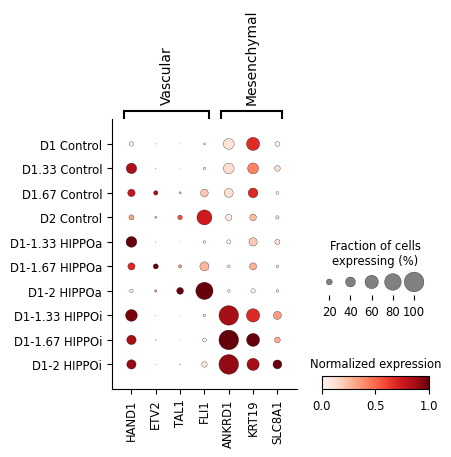

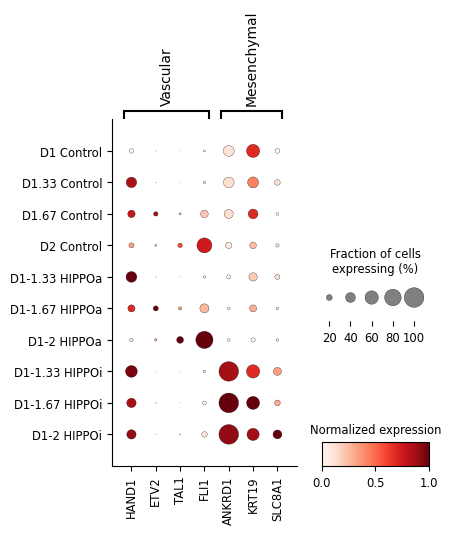

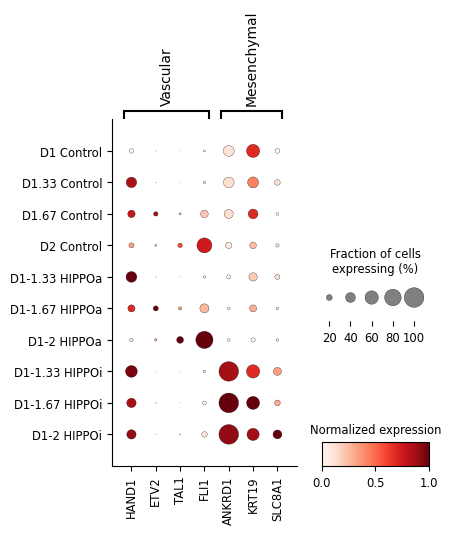

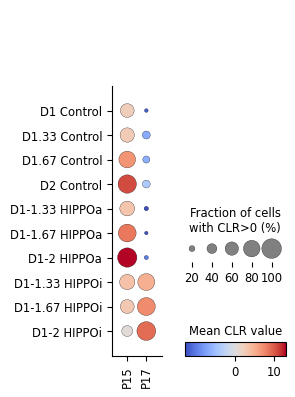

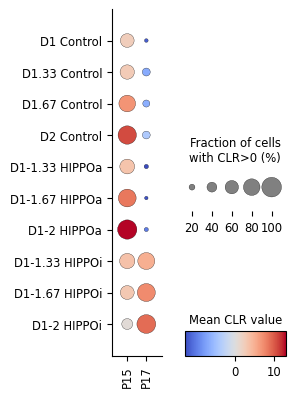

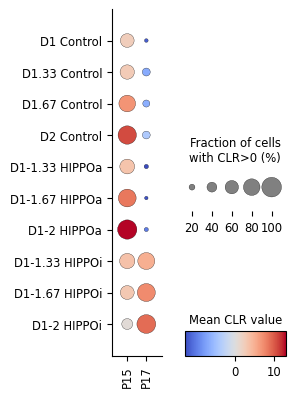

In [3]:
query_path = get_path(ctx["paths"], "hippo_timecourse.query_h5ad")
reprojected_path = get_path(
    ctx["paths"], "hippo_timecourse.reprojected_cnmf_h5ad"
)

(
    gene_dotplot_c,
    program_dotplot_c,
    gene_source_c,
    program_source_c,
    metadata_c,
) = prepare_figure4c_dotplots(
    query_path,
    reprojected_path,
)

out = panel_directory(ctx, "c")
gene_outputs = export_scanpy_dotplot(
    gene_dotplot_c,
    "c",
    "Figure_04c_D1_D2_marker_gene_dotplot",
)
program_outputs = export_scanpy_dotplot(
    program_dotplot_c,
    "c",
    "Figure_04c_D1_D2_P15_P17_dotplot",
)
gene_source_path = out / "Figure_04c_marker_gene_summary.csv"
program_source_path = out / "Figure_04c_program_summary.csv"
gene_source_c.to_csv(gene_source_path, index=False)
program_source_c.to_csv(program_source_path, index=False)

write_receipt(
    ctx,
    "c",
    status="EXECUTED_REQUIRES_MANUSCRIPT_COMPARISON",
    inputs={
        "query_h5ad": str(query_path),
        "reprojected_cnmf_h5ad": str(reprojected_path),
    },
    outputs={
        **{f"gene_{key}": value for key, value in gene_outputs.items()},
        **{f"program_{key}": value for key, value in program_outputs.items()},
        "gene_source": str(gene_source_path),
        "program_source": str(program_source_path),
    },
    parameters={
        "conditions": list(FIGURE4C_CONDITION_ORDER),
        "marker_expression": "library-size normalized, log1p, standard_scale='var'",
        "programs": list(FIGURE4C_PROGRAMS),
        "program_projection": "top_specific_200 CLR",
        "excluded_sublibrary": "s8 if present",
        **metadata_c,
    },
)

display(gene_dotplot_c)
display(program_dotplot_c)
metadata_c

## Panel d — P15/P17 and representative marker UMAPs

P15, FLI1, P17, and SLC8A1 are displayed on the integrated UMAP using a light-gray background, a `YlGnBu` foreground scale, feature-specific 99th-percentile maxima, rasterized cell points, and vector text.


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

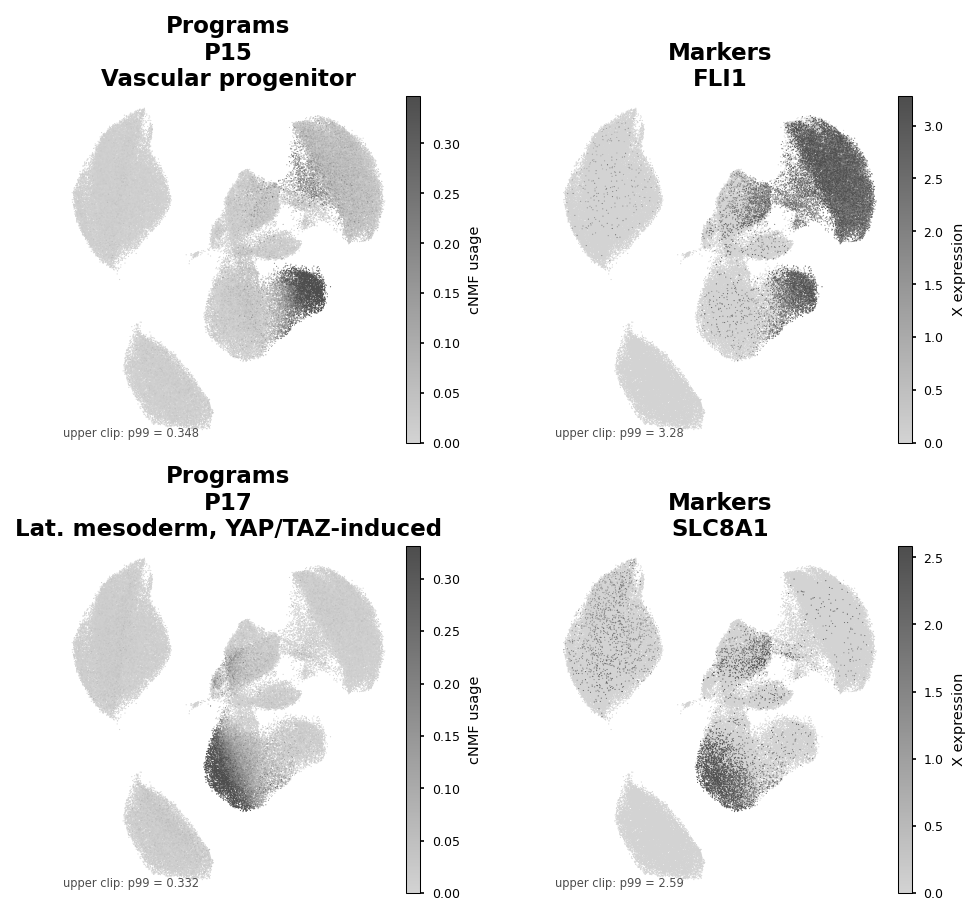

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

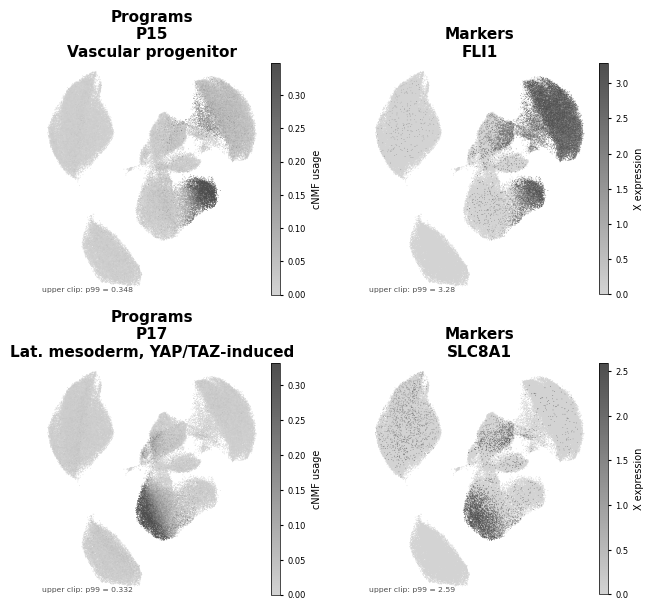

In [4]:
adata_path = get_path(ctx["paths"], "ccperturbseq.integrated_anndata")
usage_path = get_path(ctx["paths"], "ccperturbseq.cnmf_usage")
adata, usage = load_integrated_anndata(adata_path, usage_path)

plot_d, source_d = plot_figure4d_feature_umaps(adata, usage)
out = panel_directory(ctx, "d")
outputs_d = export_plotnine(
    plot_d,
    "d",
    "Figure_04d_P15_P17_FLI1_SLC8A1_umaps",
)

source_paths_d = {}
for name, table in source_d.items():
    path = out / f"Figure_04d_{name}_source.csv.gz"
    table.to_csv(path, compression="gzip")
    source_paths_d[name] = str(path)

write_receipt(
    ctx,
    "d",
    status="SOURCE_STYLE_RECOVERED_REQUIRES_SHERLOCK_EXECUTION",
    inputs={
        "anndata": str(adata_path),
        "usage": str(usage_path),
    },
    outputs={**outputs_d, **source_paths_d},
    parameters={
        "features": [str(feature) for _, feature, _ in FIGURE4D_FEATURES],
        "cmap": "YlGnBu",
        "vmax": "feature-specific p99",
        "plotting_backend": "plotnine",
    },
)

display(plot_d)

## Panel e — integrated P15/P17 annotation

The annotation combines the cNMF regulator-effect workbook, final `030526` consensus spectra, the minimum-10-carrier day-specific motif-enrichment table, the motif-cluster map, and compiled MoDISco contribution-weight matrices. It displays the top three D2-specific regulators per program, the manuscript marker genes, and the top five motifs per program. The complete motif union is exported together with the panel source tables for downstream figure layout.


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

,program,rank_within_program,gene,selection_source
0,15,1,CBLL1,Top 5 specific regulators (FDR<0.1) D2
1,15,2,STAG2,Top 5 specific regulators (FDR<0.1) D2
2,15,3,PLCG1,Top 5 specific regulators (FDR<0.1) D2
3,17,1,TBX3,Top 5 specific regulators (FDR<0.1) D2
4,17,2,DROSHA,Top 5 specific regulators (FDR<0.1) D2
5,17,3,SRRM2,Top 5 specific regulators (FDR<0.1) D2


,program,rank_within_program,gene,consensus_program_offset,raw_consensus_row,matrix_gene,loading
0,15,1,ETV2,1,16,ETV2,0.000485
1,15,2,TAL1,1,16,TAL1,0.001922
2,15,3,FLI1,1,16,FLI1,0.001673
3,17,1,SLC8A1,1,18,SLC8A1,0.002513
4,17,2,KRT19,1,18,KRT19,0.001446
5,17,3,ANKRD1,1,18,ANKRD1,0.000699
6,17,4,HAND1,1,18,HAND1,0.000740


,program,rank_within_program,motif,q_value,neg_log10_q,auc,significance,selection_rule
0,15,1,ETV-ELF-NFAT-ELK_0,1.820964e-37,36.739699,0.768336,***,top 5 motifs by q-value regardless of signific...
1,15,2,GATA_0,8.263788e-17,16.082821,0.687423,***,top 5 motifs by q-value regardless of signific...
2,15,3,ZNF_9,3.962205e-04,3.402063,0.594934,***,top 5 motifs by q-value regardless of signific...
3,15,4,ZNF813,1.813251e-03,2.741542,0.614710,**,top 5 motifs by q-value regardless of signific...
4,15,5,SOX_0,2.108812e-03,2.675962,0.596280,**,top 5 motifs by q-value regardless of signific...
5,17,1,GATA_0,1.956237e-14,13.708578,0.675480,***,top 5 motifs by q-value regardless of signific...
6,17,2,ETV-ELF-NFAT-ELK_0,3.066331e-09,8.513381,0.634461,***,top 5 motifs by q-value regardless of signific...
7,17,3,ZNF_9,2.853759e-07,6.544583,0.626781,***,top 5 motifs by q-value regardless of signific...
8,17,4,TEAD_0,4.932571e-06,5.306927,0.628407,***,top 5 motifs by q-value regardless of signific...
9,17,5,HOX-CDX_0,1.459669e-03,2.835746,0.592032,**,top 5 motifs by q-value regardless of signific...


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

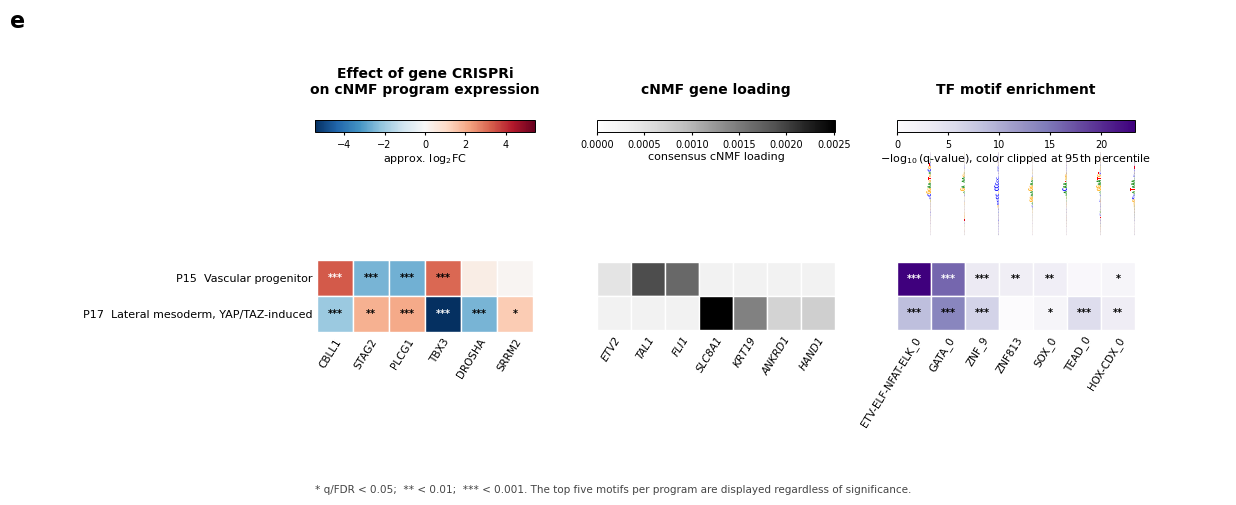

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

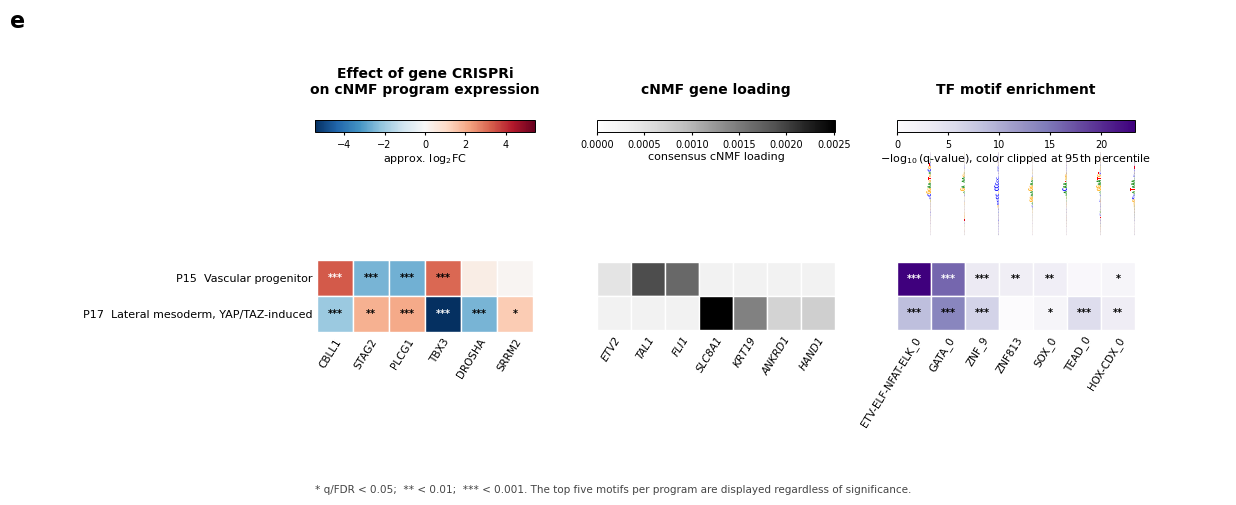

In [5]:
spectra_path = get_path(ctx["paths"], "ccperturbseq.cnmf_spectra")
motif_path = get_path(ctx["paths"], "multiome.enhancer_enrichment_results")
cluster_map_path = get_path(ctx["paths"], "multiome.cluster_motif_map")
modisco_h5_path = get_path(ctx["paths"], "multiome.modisco_compiled_h5")

figure_e, source_e, metadata_e = make_figure4e_annotation(
    workbook_path=workbook,
    spectra_path=spectra_path,
    motif_path=motif_path,
    cluster_map_path=cluster_map_path,
    modisco_h5_path=modisco_h5_path,
    top_motifs_per_program=5,
)

out = panel_directory(ctx, "e")
outputs_e = export_matplotlib(
    figure_e,
    "e",
    "Figure_04e_P15_P17_integrated_annotation_top5_motifs",
)
source_paths_e = {}
for name, table in source_e.items():
    path = out / f"Figure_04e_{name}.csv"
    table.to_csv(path)
    source_paths_e[name] = str(path)

write_receipt(
    ctx,
    "e",
    status="SOURCE_WORKFLOW_PORTED_REQUIRES_SHERLOCK_EXECUTION",
    inputs={
        "workbook": str(workbook),
        "workbook_sha256": EXPECTED_WORKBOOK_SHA256,
        "spectra": str(spectra_path),
        "motif_enrichment": str(motif_path),
        "cluster_map": str(cluster_map_path),
        "modisco_h5": str(modisco_h5_path),
    },
    outputs={**outputs_e, **source_paths_e},
    parameters={
        "day": "D2",
        "programs": ["P15", "P17"],
        "markers_P15": ["ETV2", "TAL1", "FLI1"],
        "markers_P17": ["SLC8A1", "KRT19", "ANKRD1", "HAND1"],
        "top_regulators_per_program": 3,
        "top_motifs_per_program": 5,
        "motif_selection_requires_significance": False,
        "motif_value": "-log10(BH q-value)",
        "motif_color_clipping": "95th percentile",
        "motif_logo_rotation_degrees": 90,
        **metadata_e,
    },
)

display(source_e["regulator_selection"])
display(source_e["marker_selection"])
display(source_e["motif_selection"])
figure_e